# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Frisca Angellita
- **Email:** frisca.angel18@gmail.com
- **ID Dicoding:** frisca_angellita

**Fokus proyek:** memahami pola permintaan penyewaan sepeda berdasarkan waktu (jam & tipe hari), musim, dan kondisi cuaca untuk mendukung perencanaan armada dan redistribusi sepeda.

---

### Daftar Isi
1. Menentukan Pertanyaan Bisnis
2. Import Semua Packages/Library yang Digunakan
3. Data Wrangling (Gathering → Assessing → Cleaning)
4. Exploratory Data Analysis (EDA)
5. Visualization & Explanatory Analysis
6. Analisis Lanjutan (Opsional)
7. Conclusion & Recommendation

## Menentukan Pertanyaan Bisnis

**Latar belakang.** Dataset Bike Sharing merekam penyewaan sepeda (sistem Capital Bikeshare) di Washington D.C. pada 2011–2012. Bagi pengelola layanan, dua keputusan operasional yang paling bergantung pada pola permintaan adalah **(a) kapan dan di mana sepeda harus diredistribusi** serta **(b) berapa kapasitas armada yang perlu disiapkan** pada musim dan kondisi cuaca tertentu.

**Pertanyaan bisnis (SMART):**

1. **Pola waktu.** Selama periode 1 Januari 2011 – 31 Desember 2012, pada jam berapa rata-rata penyewaan per jam mencapai puncak pada **hari kerja** dibandingkan **akhir pekan/hari libur**, dan berapa selisih rata-rata penyewaan pada jam-jam puncak tersebut? Hasilnya digunakan untuk menyusun jadwal redistribusi sepeda.
2. **Musim dan cuaca.** Selama periode 1 Januari 2011 – 31 Desember 2012, berapa rata-rata penyewaan harian pada setiap musim dan kategori cuaca, musim mana yang tertinggi dan terendah, serta berapa persen penurunan permintaan saat cuaca hujan/salju ringan dibandingkan cuaca cerah? Hasilnya digunakan untuk perencanaan kapasitas musiman dan mitigasi saat cuaca buruk.

**Pemetaan elemen SMART**

| Elemen | Pertanyaan 1 (pola waktu) | Pertanyaan 2 (musim & cuaca) |
|---|---|---|
| **Specific** | Jam puncak hari kerja vs akhir pekan/libur | Rata-rata sewa harian per musim & kategori cuaca |
| **Measurable** | Rata-rata sewa per jam, jam puncak, selisih puncak | Rata-rata sewa per hari, persentase perubahan vs cuaca cerah |
| **Action-oriented** | Jadwal & lokasi redistribusi sepeda | Kapasitas armada musiman & mitigasi cuaca buruk |
| **Relevant** | Ketersediaan sepeda pada jam sibuk | Perencanaan kapasitas & pendapatan layanan |
| **Time-bound** | Jan 2011 – Des 2012 | Jan 2011 – Des 2012 |

## Import Semua Packages/Library yang Digunakan

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.labelsize': 11, 'axes.grid.axis': 'y'})
ribuan = FuncFormatter(lambda x, _: f'{x:,.0f}')   # format sumbu: 1,000

# Palet warna konsisten di seluruh visualisasi
WARNA_KERJA, WARNA_LIBUR = '#2563EB', '#F59E0B'
WARNA_UTAMA, WARNA_SOROT, WARNA_REDUP = '#2563EB', '#DC2626', '#94A3B8'

## Data Wrangling

### Gathering Data

Data terdiri dari dua file pada folder `data/`:

- `day.csv` — agregasi **harian** (satu baris per tanggal).
- `hour.csv` — agregasi **per jam** (satu baris per tanggal-jam).

**Kamus data (kolom utama)**

| Kolom | Keterangan |
|---|---|
| `instant` | Nomor urut record |
| `dteday` | Tanggal |
| `season` | Kode musim (1–4) |
| `yr` | Tahun (0 = 2011, 1 = 2012) |
| `mnth` / `hr` | Bulan (1–12) / jam (0–23, hanya di `hour.csv`) |
| `holiday` | 1 jika hari libur nasional |
| `weekday` | Hari dalam pekan (0 = Minggu … 6 = Sabtu) |
| `workingday` | 1 jika bukan akhir pekan dan bukan hari libur |
| `weathersit` | Kategori cuaca (1 cerah, 2 berawan/berkabut, 3 hujan/salju ringan, 4 hujan lebat/badai salju) |
| `temp`, `atemp` | Suhu dan suhu terasa, **ternormalisasi** |
| `hum`, `windspeed` | Kelembapan dan kecepatan angin, **ternormalisasi** |
| `casual`, `registered`, `cnt` | Penyewa tidak terdaftar, terdaftar, dan total (`cnt = casual + registered`) |

In [4]:
DATA_DIR = 'data'
day_raw = pd.read_csv(os.path.join(DATA_DIR, 'day.csv'))
hour_raw = pd.read_csv(os.path.join(DATA_DIR, 'hour.csv'))

print(f'day.csv  : {day_raw.shape[0]:,} baris x {day_raw.shape[1]} kolom')
print(f'hour.csv : {hour_raw.shape[0]:,} baris x {hour_raw.shape[1]} kolom')
print('\nCuplikan day.csv')
display(day_raw.head())
print('Cuplikan hour.csv')
display(hour_raw.head())

day.csv  : 731 baris x 16 kolom
hour.csv : 17,379 baris x 17 kolom

Cuplikan day.csv


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


Cuplikan hour.csv


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


In [5]:
print('=== Info day.csv ===')
day_raw.info()
print('\n=== Info hour.csv ===')
hour_raw.info()

=== Info day.csv ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== Info hour.csv ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex:

**Insight gathering data**
- `day.csv` berisi **731 baris** (satu baris per tanggal, 2011-01-01 s.d. 2012-12-31), sedangkan `hour.csv` berisi **17,379 baris** untuk analisis pola intrahari.
- Kedua tabel memiliki struktur kolom yang hampir sama; `hour.csv` hanya menambah kolom `hr`.
- Kolom `dteday` terbaca sebagai teks, sedangkan `temp`, `atemp`, `hum`, dan `windspeed` berupa nilai **ternormalisasi** sehingga perlu dikonversi ke satuan asli agar mudah ditafsirkan.

### Assessing Data

Pemeriksaan kualitas dilakukan secara bertahap: (1) kelengkapan & duplikasi, (2) konsistensi antar kolom/tabel, (3) validitas nilai, (4) konsistensi label kategori, dan (5) nilai ekstrem (outlier).

**(1) Missing value dan data duplikat**

In [6]:
def ringkasan_kualitas(frame, kunci):
    return {
        'Jumlah baris': len(frame),
        'Total missing value': int(frame.isna().sum().sum()),
        'Baris duplikat (seluruh kolom)': int(frame.duplicated().sum()),
        'Duplikat pada kunci (tanggal atau tanggal+jam)': int(frame.duplicated(subset=kunci).sum()),
        'Tipe data dteday': str(frame['dteday'].dtype),
    }

kualitas = pd.DataFrame({
    'day.csv': ringkasan_kualitas(day_raw, ['dteday']),
    'hour.csv': ringkasan_kualitas(hour_raw, ['dteday', 'hr']),
}).astype(str)
display(kualitas)

,day.csv,hour.csv
Jumlah baris,731,17379
Total missing value,0,0
Baris duplikat (seluruh kolom),0,0
Duplikat pada kunci (tanggal atau tanggal+jam),0,0
Tipe data dteday,object,object


**(2) Konsistensi antar kolom dan antar tabel**

In [7]:
tgl = pd.to_datetime(day_raw['dteday'])
aturan_kerja = (day_raw['weekday'].between(1, 5) & day_raw['holiday'].eq(0)).astype(int)
total_jam_per_hari = hour_raw.groupby('dteday')['cnt'].sum()
total_hari = day_raw.set_index('dteday')['cnt']

cek_konsistensi = pd.Series({
    'day: cnt != casual + registered': int((day_raw['cnt'] != day_raw['casual'] + day_raw['registered']).sum()),
    'hour: cnt != casual + registered': int((hour_raw['cnt'] != hour_raw['casual'] + hour_raw['registered']).sum()),
    'day: yr tidak cocok dengan tahun pada dteday': int((day_raw['yr'] != tgl.dt.year - 2011).sum()),
    'day: mnth tidak cocok dengan bulan pada dteday': int((day_raw['mnth'] != tgl.dt.month).sum()),
    'day: weekday tidak cocok dengan dteday': int((day_raw['weekday'] != (tgl.dt.dayofweek + 1) % 7).sum()),
    'day: workingday tidak sesuai aturan (Senin-Jumat, bukan libur)': int((day_raw['workingday'] != aturan_kerja).sum()),
    'Tanggal dengan total per jam != cnt harian': int((total_jam_per_hari != total_hari.reindex(total_jam_per_hari.index)).sum()),
    'Tanggal pada hour.csv yang tidak ada di day.csv': int((~hour_raw['dteday'].isin(day_raw['dteday'])).sum()),
}, name='jumlah_baris_bermasalah')
display(cek_konsistensi.to_frame())

# Kelengkapan data per jam: seharusnya 731 hari x 24 jam
jam_diharapkan = len(day_raw) * 24
jam_tercatat = len(hour_raw)
jam_hilang = jam_diharapkan - jam_tercatat
baris_per_hari = hour_raw.groupby('dteday').size()
print(f'Jumlah baris per jam yang diharapkan : {jam_diharapkan:,}')
print(f'Jumlah baris per jam yang tercatat   : {jam_tercatat:,}')
print(f'Baris jam yang hilang                : {jam_hilang:,}  (tersebar pada {int((baris_per_hari < 24).sum())} tanggal)')
print(f'Nilai minimum cnt pada hour.csv      : {hour_raw["cnt"].min()}  -> tidak ada baris dengan penyewaan 0')

kombinasi = set(zip(hour_raw['dteday'], hour_raw['hr']))
hilang = [(t, j) for t in day_raw['dteday'] for j in range(24) if (t, j) not in kombinasi]
sebaran_jam_hilang = pd.Series([j for _, j in hilang]).value_counts().sort_index()
print('\nSebaran jam yang hilang (jam: jumlah):')
print(sebaran_jam_hilang.to_dict())

,jumlah_baris_bermasalah
day: cnt != casual + registered,0
hour: cnt != casual + registered,0
day: yr tidak cocok dengan tahun pada dteday,0
day: mnth tidak cocok dengan bulan pada dteday,0
day: weekday tidak cocok dengan dteday,0
"day: workingday tidak sesuai aturan (Senin-Jumat, bukan libur)",0
Tanggal dengan total per jam != cnt harian,0
Tanggal pada hour.csv yang tidak ada di day.csv,0


Jumlah baris per jam yang diharapkan : 17,544
Jumlah baris per jam yang tercatat   : 17,379
Baris jam yang hilang                : 165  (tersebar pada 76 tanggal)
Nilai minimum cnt pada hour.csv      : 1  -> tidak ada baris dengan penyewaan 0

Sebaran jam yang hilang (jam: jumlah):
{0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 2, 14: 2, 15: 2, 16: 1, 17: 1, 18: 3, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3}


**(3) Validitas nilai (rentang dan kategori)**

In [8]:
print('Rentang nilai variabel cuaca pada day.csv (ternormalisasi):')
display(day_raw[['temp', 'atemp', 'hum', 'windspeed']].describe().loc[['min', '25%', '50%', '75%', 'max']])

hum0_day = day_raw.loc[day_raw['hum'] == 0, ['dteday', 'hum', 'temp', 'cnt']]
hum0_hour = hour_raw.loc[hour_raw['hum'] == 0, 'dteday']
print('\nKelembapan = 0 pada day.csv:')
display(hum0_day)
print(f'Kelembapan = 0 pada hour.csv: {len(hum0_hour)} baris, tanggal unik: {sorted(hum0_hour.unique())}')
print('Kelembapan harian di sekitar tanggal tersebut:')
display(day_raw.loc[day_raw['dteday'].between('2011-03-08', '2011-03-12'), ['dteday', 'hum']])

print('\nDistribusi kategori cuaca (weathersit):')
display(pd.DataFrame({'day.csv': day_raw['weathersit'].value_counts().sort_index(),
                      'hour.csv': hour_raw['weathersit'].value_counts().sort_index()}).fillna(0).astype(int))

Rentang nilai variabel cuaca pada day.csv (ternormalisasi):


,temp,atemp,hum,windspeed
min,0.06,0.08,0.00,0.02
25%,0.34,0.34,0.52,0.13
50%,0.50,0.49,0.63,0.18
75%,0.66,0.61,0.73,0.23
max,0.86,0.84,0.97,0.51



Kelembapan = 0 pada day.csv:


,dteday,hum,temp,cnt
68,2011-03-10,0.00,0.39,623


Kelembapan = 0 pada hour.csv: 22 baris, tanggal unik: ['2011-03-10']
Kelembapan harian di sekitar tanggal tersebut:


,dteday,hum
66,2011-03-08,0.42
67,2011-03-09,0.78
68,2011-03-10,0.00
69,2011-03-11,0.65
70,2011-03-12,0.59



Distribusi kategori cuaca (weathersit):


,day.csv,hour.csv
weathersit,,
1,463,11413
2,247,4544
3,21,1419
4,0,3


**(4) Konsistensi label musim (`season`)**

In [9]:
bulan = pd.to_datetime(day_raw['dteday']).dt.month
print('Jumlah hari per bulan untuk tiap kode musim:')
display(pd.crosstab(bulan.rename('bulan'), day_raw['season'].rename('kode_season')))

suhu_c = (day_raw['temp'] * 47 - 8).groupby(day_raw['season']).mean().round(1).rename('rata2_suhu_C')
display(suhu_c.to_frame())

Jumlah hari per bulan untuk tiap kode musim:


kode_season,1,2,3,4
bulan,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


,rata2_suhu_C
season,
1,6.00
2,17.60
3,25.20
4,11.90


**(5) Nilai ekstrem (outlier) dengan aturan IQR**

In [10]:
def tabel_outlier(frame, kolom):
    baris = []
    for col in kolom:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((frame[col] < batas_bawah) | (frame[col] > batas_atas)).sum())
        baris.append({'kolom': col, 'batas_bawah': batas_bawah, 'batas_atas': batas_atas,
                      'jumlah_outlier': n, 'persen': n / len(frame) * 100})
    return pd.DataFrame(baris).set_index('kolom')

print('day.csv')
tabel_out = tabel_outlier(day_raw, ['cnt', 'casual', 'registered', 'hum', 'windspeed'])
display(tabel_out)

# Apakah outlier casual terkonsentrasi pada hari non-kerja? (indikasi lonjakan yang valid)
q1, q3 = day_raw['casual'].quantile([0.25, 0.75])
out_casual = day_raw[day_raw['casual'] > q3 + 1.5 * (q3 - q1)]
persen_nonkerja = (out_casual['workingday'] == 0).mean() * 100
print(f'\nOutlier casual: {len(out_casual)} hari, {persen_nonkerja:.0f}% di antaranya jatuh pada akhir pekan/hari libur.')

print('\nTiga hari dengan permintaan terendah:')
display(day_raw.nsmallest(3, 'cnt')[['dteday', 'cnt', 'weathersit', 'windspeed']])

day.csv


,batas_bawah,batas_atas,jumlah_outlier,persen
kolom,,,,
cnt,"-1,054.00","10,162.00",0,0.00
casual,-855.25,"2,266.75",44,6.02
registered,-922.25,"8,195.75",0,0.00
hum,0.20,1.05,2,0.27
windspeed,-0.01,0.38,13,1.78



Outlier casual: 44 hari, 98% di antaranya jatuh pada akhir pekan/hari libur.

Tiga hari dengan permintaan terendah:


,dteday,cnt,weathersit,windspeed
667,2012-10-29,22,3,0.36
26,2011-01-27,431,1,0.11
725,2012-12-26,441,3,0.32


**Temuan assessing dan rencana penanganan**

| No | Masalah | Jenis | Bukti | Tindakan pada tahap cleaning |
|---|---|---|---|---|
| 1 | Tipe `dteday` masih teks | Inconsistent type | `dtype` = `str` | Konversi ke `datetime` |
| 2 | Kelembapan `hum = 0` pada 2011-03-10 | Invalid / inaccurate value | Kelembapan nol tidak realistis; hari-hari sekitarnya bernilai 0.42–0.78. Muncul pada 22 baris di `hour.csv` | Ganti dengan `NaN`, lalu imputasi interpolasi linear antar-hari |
| 3 | **165 baris jam tidak ada** di `hour.csv` (tersebar di 76 tanggal) | Missing records (implisit) | Total baris 17,379 dari seharusnya 17,544; `cnt` minimum = 1, sehingga jam tanpa penyewaan tidak tercatat. Jam yang hilang terkonsentrasi pada dini hari | Lengkapi grid tanggal x jam; isi `casual`, `registered`, `cnt` = 0. Tanpa langkah ini rata-rata per jam, terutama dini hari, **terlalu tinggi** |
| 4 | Label musim pada dokumentasi tidak sesuai kalender | Inconsistent / inaccurate value | Kode 1 muncul pada Des–Mar dengan suhu rata-rata terendah (6.0 °C), kode 3 pada Jun–Sep dengan suhu tertinggi (25.2 °C) | Beri label berdasarkan bulan/suhu aktual: 1 = Dingin, 2 = Semi, 3 = Panas, 4 = Gugur |
| 5 | Kategori cuaca 4 hanya 3 baris jam dan tidak ada di data harian | Sparse category | Lihat tabel distribusi `weathersit` | Dipertahankan pada data jam; analisis harian memakai kategori 1–3 |
| 6 | Variabel cuaca ternormalisasi | Satuan tidak intuitif | `temp`, `atemp`, `hum`, `windspeed` berada pada rentang 0–1 | Konversi ke °C, %, dan km/jam sesuai dokumentasi dataset |
| 7 | Outlier `casual` (44 hari), `windspeed` (13 hari), `hum` (2 hari) | Outlier | 98% outlier `casual` terjadi pada hari non-kerja, sehingga lonjakan tampak wajar. Outlier `hum` salah satunya adalah nilai invalid pada temuan no. 2 | **Dipertahankan**: lonjakan permintaan adalah kejadian operasional yang valid |

**Hal yang sudah valid:** tidak ada missing value eksplisit maupun baris duplikat; `cnt = casual + registered` konsisten pada kedua tabel; `yr`, `mnth`, `weekday`, dan `workingday` konsisten dengan tanggal; total `hour.csv` per hari identik dengan `cnt` pada `day.csv`.

### Cleaning Data

Pembersihan dilakukan secara **konservatif dan terdokumentasi**: tidak ada baris data asli yang dihapus, outlier yang valid dipertahankan, dan setiap perubahan dibandingkan sebelum-sesudahnya.

**Langkah 1 — Konversi tipe tanggal dan perbaikan kelembapan invalid**

In [11]:
day_df = day_raw.copy()
hour_df = hour_raw.copy()

# 1a. Konversi tanggal
for frame in (day_df, hour_df):
    frame['dteday'] = pd.to_datetime(frame['dteday'], errors='coerce')
assert day_df['dteday'].notna().all() and hour_df['dteday'].notna().all()

# 1b. Kelembapan = 0 dianggap invalid -> NaN -> interpolasi linear antar-hari
tgl_invalid = day_df.loc[day_df['hum'].eq(0), 'dteday']
day_df = day_df.sort_values('dteday').reset_index(drop=True)
nilai_sebelum = day_df.loc[day_df['dteday'].isin(tgl_invalid), 'hum'].tolist()
day_df.loc[day_df['hum'].eq(0), 'hum'] = np.nan
day_df['hum'] = day_df['hum'].interpolate(method='linear')
nilai_sesudah = day_df.loc[day_df['dteday'].isin(tgl_invalid), 'hum'].round(4).tolist()
print(f'Kelembapan harian pada {[t.date().isoformat() for t in tgl_invalid]}: {nilai_sebelum} -> {nilai_sesudah}')

# Pada data jam, nilai invalid pada tanggal yang sama diisi dengan kelembapan harian hasil imputasi
hum_harian = day_df.set_index('dteday')['hum']
mask_hum0_hour = hour_df['hum'].eq(0)
hour_df.loc[mask_hum0_hour, 'hum'] = hour_df.loc[mask_hum0_hour, 'dteday'].map(hum_harian)
print(f'Baris jam diperbaiki: {int(mask_hum0_hour.sum())} | sisa hum = 0: day={int((day_df.hum == 0).sum())}, hour={int((hour_df.hum == 0).sum())}')

Kelembapan harian pada ['2011-03-10']: [0.0] -> [0.7125]
Baris jam diperbaiki: 22 | sisa hum = 0: day=0, hour=0


**Langkah 2 — Melengkapi jam yang tidak tercatat (penyewaan = 0)**

Kolom `instant` pada data jam tidak dipertahankan karena hanya nomor urut record dan tidak bermakna untuk baris yang baru ditambahkan.

In [12]:
kolom_kalender = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday']

grid = pd.MultiIndex.from_product([day_df['dteday'], range(24)], names=['dteday', 'hr']).to_frame(index=False)
hour_full = grid.merge(hour_df.drop(columns='instant'), on=['dteday', 'hr'], how='left')
hour_full['jam_tidak_tercatat'] = hour_full['cnt'].isna()

# Jam tanpa catatan = tidak ada penyewaan
for col in ['casual', 'registered', 'cnt']:
    hour_full[col] = hour_full[col].fillna(0).astype(int)

# Atribut kalender dilengkapi dari data harian; atribut cuaca per jam dibiarkan kosong (tidak diketahui)
peta_kalender = day_df.set_index('dteday')[kolom_kalender]
for col in kolom_kalender:
    hour_full[col] = hour_full[col].fillna(hour_full['dteday'].map(peta_kalender[col])).astype(int)

n_sebelum, n_sesudah = len(hour_df), len(hour_full)
rata_sebelum = hour_df.groupby('hr')['cnt'].mean()
rata_sesudah = hour_full.groupby('hr')['cnt'].mean()
hour_df = hour_full
print(f'Baris data jam: {n_sebelum:,} -> {n_sesudah:,} (+{n_sesudah - n_sebelum:,} baris jam tanpa penyewaan)')

dampak = pd.DataFrame({'sebelum_dilengkapi': rata_sebelum, 'sesudah_dilengkapi': rata_sesudah})
dampak['selisih_pct'] = (dampak['sesudah_dilengkapi'] / dampak['sebelum_dilengkapi'] - 1) * 100
print('\nDampak pada rata-rata sewa per jam (5 jam dengan perubahan terbesar):')
display(dampak.reindex(dampak['selisih_pct'].abs().sort_values(ascending=False).index).head(5).round(2))

Baris data jam: 17,379 -> 17,544 (+165 baris jam tanpa penyewaan)

Dampak pada rata-rata sewa per jam (5 jam dengan perubahan terbesar):


,sebelum_dilengkapi,sesudah_dilengkapi,selisih_pct
hr,,,
3,11.73,11.18,-4.65
4,6.35,6.06,-4.65
2,22.87,22.37,-2.19
5,19.89,19.51,-1.92
1,33.38,33.06,-0.96


**Langkah 3 — Pelabelan kategori, konversi satuan, dan fitur turunan**

In [13]:
season_labels = {1: 'Musim Dingin', 2: 'Musim Semi', 3: 'Musim Panas', 4: 'Musim Gugur'}
weather_labels = {1: 'Cerah / sedikit awan', 2: 'Berawan / berkabut',
                  3: 'Hujan ringan / salju ringan', 4: 'Hujan lebat / badai salju'}
nama_bulan = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
              7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}
nama_hari = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}

for frame in (day_df, hour_df):
    frame['season_label'] = pd.Categorical(frame['season'].map(season_labels),
                                           categories=list(season_labels.values()), ordered=True)
    frame['weather_label'] = pd.Categorical(frame['weathersit'].map(weather_labels),
                                            categories=list(weather_labels.values()), ordered=True)
    frame['tahun'] = frame['yr'].map({0: 2011, 1: 2012})
    frame['bulan'] = frame['mnth'].map(nama_bulan)
    frame['hari'] = frame['weekday'].map(nama_hari)
    frame['day_type'] = np.where(frame['workingday'].eq(1), 'Hari kerja', 'Akhir pekan/libur')
    # Konversi ke satuan asli (rumus normalisasi pada dokumentasi dataset)
    frame['temp_c'] = frame['temp'] * 47 - 8        # t_min = -8,  t_max = 39
    frame['atemp_c'] = frame['atemp'] * 66 - 16     # t_min = -16, t_max = 50
    frame['hum_pct'] = frame['hum'] * 100
    frame['windspeed_kmh'] = frame['windspeed'] * 67

day_df['persen_registered'] = day_df['registered'] / day_df['cnt'] * 100
hour_df['segmen_waktu'] = pd.cut(hour_df['hr'], bins=[-1, 5, 9, 15, 19, 23],
                                 labels=['Dini hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)',
                                         'Sore (16-19)', 'Malam (20-23)'])

display(day_df[['dteday', 'season', 'season_label', 'weathersit', 'weather_label', 'temp', 'temp_c',
                'hum_pct', 'windspeed_kmh', 'day_type']].head())

,dteday,season,season_label,weathersit,weather_label,temp,temp_c,hum_pct,windspeed_kmh,day_type
0,2011-01-01,1,Musim Dingin,2,Berawan / berkabut,0.34,8.18,80.58,10.75,Akhir pekan/libur
1,2011-01-02,1,Musim Dingin,2,Berawan / berkabut,0.36,9.08,69.61,16.65,Akhir pekan/libur
2,2011-01-03,1,Musim Dingin,1,Cerah / sedikit awan,0.20,1.23,43.73,16.64,Hari kerja
3,2011-01-04,1,Musim Dingin,1,Cerah / sedikit awan,0.20,1.40,59.04,10.74,Hari kerja
4,2011-01-05,1,Musim Dingin,1,Cerah / sedikit awan,0.23,2.67,43.70,12.52,Hari kerja


**Langkah 4 — Validasi hasil cleaning dan penyimpanan data untuk dashboard**

In [14]:
# Validasi pasca-cleaning
assert (day_df['cnt'] == day_df['casual'] + day_df['registered']).all()
assert (hour_df['cnt'] == hour_df['casual'] + hour_df['registered']).all()
assert len(hour_df) == len(day_df) * 24
assert not hour_df.duplicated(subset=['dteday', 'hr']).any()
assert (day_df['hum'] > 0).all() and (hour_df['hum'].dropna() > 0).all()
assert day_df['season_label'].notna().all() and day_df['weather_label'].notna().all()
# Total per hari pada data jam harus tetap sama dengan data harian
assert (hour_df.groupby('dteday')['cnt'].sum().values == day_df.set_index('dteday')['cnt'].sort_index().values).all()

print('Seluruh validasi lolos.')
print(f'Ukuran akhir  -> day_df: {day_df.shape} | hour_df: {hour_df.shape}')
print(f'Periode data  -> {day_df.dteday.min().date()} s.d. {day_df.dteday.max().date()}')

# Simpan data bersih agar dashboard memakai definisi data yang sama dengan notebook
os.makedirs('dashboard', exist_ok=True)
day_df.to_csv('dashboard/day_data.csv', index=False)
hour_df.to_csv('dashboard/main_data.csv', index=False)
print('Tersimpan: dashboard/day_data.csv dan dashboard/main_data.csv')

Seluruh validasi lolos.
Ukuran akhir  -> day_df: (731, 27) | hour_df: (17544, 28)
Periode data  -> 2011-01-01 s.d. 2012-12-31
Tersimpan: dashboard/day_data.csv dan dashboard/main_data.csv


**Insight cleaning**
- Tanggal sudah bertipe `datetime`; kelembapan invalid (0) pada 2011-03-10 diperbaiki menjadi ≈ 0.71 melalui interpolasi, sehingga variabel kelembapan tidak lagi menyesatkan.
- Data jam dilengkapi dari 17,379 menjadi **17,544 baris** (731 hari x 24 jam). Langkah ini penting karena tanpa jam bernilai nol, rata-rata per jam dini hari terlalu tinggi hingga **4.7%** (pada jam 03:00). Dampaknya kecil pada jam sibuk, tetapi langkah ini membuat rata-rata per jam tidak bias.
- Label musim dikoreksi mengikuti kalender dan suhu aktual, sehingga interpretasi tidak terbalik (kode 1 adalah musim terdingin, bukan musim semi).
- Kolom `instant` pada data jam dibuang karena hanya nomor urut record (tidak lagi valid setelah baris dilengkapi).
- Satuan cuaca dikonversi ke °C, %, dan km/jam; fitur turunan (`day_type`, `segmen_waktu`, `tahun`, `persen_registered`) disiapkan untuk EDA.
- Tidak ada baris data asli yang dibuang; outlier valid dipertahankan.

## Exploratory Data Analysis (EDA)

### Gambaran umum

Rangkuman statistik digunakan untuk memahami skala dan variasi penyewaan sebelum menjawab pertanyaan bisnis.

In [15]:
display(day_df[['casual', 'registered', 'cnt', 'temp_c', 'hum_pct', 'windspeed_kmh']].describe().T.round(2))

total_sewa = day_df['cnt'].sum()
persen_registered_total = day_df['registered'].sum() / total_sewa * 100
per_tahun = day_df.groupby('tahun')['cnt'].agg(total='sum', rata2_per_hari='mean')
pertumbuhan_yoy = (per_tahun.loc[2012, 'total'] / per_tahun.loc[2011, 'total'] - 1) * 100

print(f'Total penyewaan 2011-2012          : {total_sewa:,}')
print(f'Porsi pengguna registered          : {persen_registered_total:.1f}%')
print(f'Pertumbuhan total sewa 2012 vs 2011: {pertumbuhan_yoy:.1f}%')
display(per_tahun.round(1))

,count,mean,std,min,25%,50%,75%,max
casual,731.00,848.18,686.62,2.00,315.50,713.00,"1,096.00","3,410.00"
registered,731.00,"3,656.17","1,560.26",20.00,"2,497.00","3,662.00","4,776.50","6,946.00"
cnt,731.00,"4,504.35","1,937.21",22.00,"3,152.00","4,548.00","5,956.00","8,714.00"
temp_c,731.00,15.28,8.60,-5.22,7.84,15.42,22.80,32.50
hum_pct,731.00,62.89,14.06,18.79,52.10,62.75,73.02,97.25
windspeed_kmh,731.00,12.76,5.19,1.50,9.04,12.13,15.63,34.00


Total penyewaan 2011-2012          : 3,292,679
Porsi pengguna registered          : 81.2%
Pertumbuhan total sewa 2012 vs 2011: 64.9%


,total,rata2_per_hari
tahun,,
2011,1243103,"3,405.80"
2012,2049576,"5,599.90"


**Insight:** Selama dua tahun tercatat **3,292,679 penyewaan**, rata-rata **4,504 sewa per hari** (rentang 22–8,714). Pengguna terdaftar mendominasi dengan **81%** dari total sewa. Permintaan tumbuh **65%** dari 2011 ke 2012, sehingga perbandingan antar musim perlu dibaca bersama faktor tahun.

### EDA 1 — Pola permintaan per jam menurut tipe hari (Pertanyaan 1)

Teknik: *grouping* berdasarkan tipe hari dan jam, lalu menghitung rata-rata `cnt` per jam (jam tanpa penyewaan ikut dihitung sebagai 0). Nilai maksimum tiap kelompok dipakai untuk menemukan jam puncak.

In [16]:
hourly_pattern = hour_df.groupby(['day_type', 'hr'])['cnt'].mean().unstack('day_type')

peak_summary = pd.DataFrame({'jam_puncak': hourly_pattern.idxmax(),
                             'rata_rata_sewa_puncak': hourly_pattern.max()})
display(peak_summary.round(1))

# Tiga jam tertinggi pada tiap tipe hari
for tipe in hourly_pattern.columns:
    top3 = hourly_pattern[tipe].nlargest(3)
    print(f'{tipe:<18}: ' + ' | '.join(f'{j:02d}:00 = {v:,.0f}' for j, v in top3.items()))

# Puncak pagi dan sore pada hari kerja
puncak_pagi = hourly_pattern.loc[6:10, 'Hari kerja'].agg(['idxmax', 'max'])
puncak_sore = hourly_pattern.loc[15:19, 'Hari kerja'].agg(['idxmax', 'max'])
print(f'\nHari kerja - puncak pagi : {int(puncak_pagi["idxmax"]):02d}:00 ({puncak_pagi["max"]:,.0f} sewa/jam)')
print(f'Hari kerja - puncak sore : {int(puncak_sore["idxmax"]):02d}:00 ({puncak_sore["max"]:,.0f} sewa/jam)')

,jam_puncak,rata_rata_sewa_puncak
day_type,,
Akhir pekan/libur,13,372.70
Hari kerja,17,524.20


Akhir pekan/libur : 13:00 = 373 | 12:00 = 366 | 14:00 = 365
Hari kerja        : 17:00 = 524 | 18:00 = 490 | 08:00 = 473

Hari kerja - puncak pagi : 08:00 (473 sewa/jam)
Hari kerja - puncak sore : 17:00 (524 sewa/jam)


In [17]:
# Seberapa besar porsi penyewaan pada jam-jam sibuk? (07-09 dan 16-19)
jam_sibuk = hour_df['hr'].isin([7, 8, 9, 16, 17, 18, 19])
jam_siang = hour_df['hr'].between(11, 15)

porsi = pd.DataFrame({
    'porsi_jam_sibuk_(07-09 & 16-19)_%': hour_df[jam_sibuk].groupby('day_type')['cnt'].sum() / hour_df.groupby('day_type')['cnt'].sum() * 100,
    'porsi_siang_(11-15)_%': hour_df[jam_siang].groupby('day_type')['cnt'].sum() / hour_df.groupby('day_type')['cnt'].sum() * 100,
})
display(porsi.round(1))

# Komposisi pengguna per tipe hari (rata-rata per jam)
komposisi = hour_df.groupby('day_type')[['casual', 'registered']].mean()
komposisi['persen_casual'] = komposisi['casual'] / (komposisi['casual'] + komposisi['registered']) * 100
display(komposisi.round(2))

# Rata-rata sewa per jam menurut segmen waktu
segmen = hour_df.groupby(['segmen_waktu', 'day_type'], observed=True)['cnt'].mean().unstack('day_type')
display(segmen.round(1))

,porsi_jam_sibuk_(07-09 & 16-19)_%,porsi_siang_(11-15)_%
day_type,,
Akhir pekan/libur,34.80,41.10
Hari kerja,57.90,20.40


,casual,registered,persen_casual
day_type,,,
Akhir pekan/libur,57.13,123.29,31.66
Hari kerja,25.27,165.76,13.23


day_type,Akhir pekan/libur,Hari kerja
segmen_waktu,,
Dini hari (00-05),42.30,16.00
Pagi (06-09),84.80,275.70
Siang (10-15),338.90,178.60
Sore (16-19),296.70,413.50
Malam (20-23),129.10,165.10


**Insight:**
- **Hari kerja** memiliki **dua puncak** yang khas jam komuter: **08:00** (473 sewa/jam) dan **17:00** (524 sewa/jam). Puncak sore lebih tinggi sekitar 11% daripada puncak pagi.
- **Akhir pekan/libur** hanya memiliki **satu puncak lebar** pada **13:00** (373 sewa/jam), dengan permintaan relatif tinggi sepanjang 11:00–16:00. Pola ini mengarah pada penggunaan rekreasi.
- Pada jam puncak, hari kerja (524 sewa/jam) lebih tinggi **41%** dibanding puncak akhir pekan/libur (373 sewa/jam).
- Jam sibuk (07–09 dan 16–19) menyumbang **58%** penyewaan hari kerja, jauh di atas 35% pada akhir pekan/libur; sebaliknya jam 11–15 menyumbang 41% pada akhir pekan/libur.
- Komposisi pengguna berbeda: pengguna *casual* hanya **13%** dari sewa hari kerja, tetapi **32%** pada akhir pekan/libur. Hari kerja didominasi komuter terdaftar, akhir pekan lebih banyak pengguna kasual.

### EDA 2 — Pengaruh musim dan cuaca (Pertanyaan 2)

Teknik: agregasi jumlah hari, rata-rata, median, dan simpangan baku `cnt` per musim/cuaca. Persentase perubahan cuaca dihitung relatif terhadap cuaca cerah (kode 1). Karena musim, cuaca, dan tahun saling terkait, ditambahkan pengecekan silang agar kesimpulan tidak bias.

In [18]:
season_summary = (day_df.groupby('season_label', observed=True)['cnt']
                  .agg(['count', 'mean', 'median', 'std', 'min', 'max']))
season_summary['perubahan_vs_musim_tertinggi_pct'] = (season_summary['mean'] / season_summary['mean'].max() - 1) * 100
display(season_summary.round(1))

weather_summary = (day_df.groupby(['weathersit', 'weather_label'], observed=True)['cnt']
                   .agg(['count', 'mean', 'median', 'std']).reset_index())
clear_mean = weather_summary.loc[weather_summary['weathersit'].eq(1), 'mean'].iloc[0]
weather_summary['perubahan_vs_cerah_pct'] = (weather_summary['mean'] / clear_mean - 1) * 100
display(weather_summary.round(1))

# Kondisi cuaca rata-rata pada tiap kategori (menjelaskan mekanisme)
display(day_df.groupby('weather_label', observed=True)[['temp_c', 'hum_pct', 'windspeed_kmh']].mean().round(1))

,count,mean,median,std,min,max,perubahan_vs_musim_tertinggi_pct
season_label,,,,,,,
Musim Dingin,181,"2,604.10","2,209.00","1,399.90",431,7836,-53.90
Musim Semi,184,"4,992.30","4,941.50","1,696.00",795,8362,-11.60
Musim Panas,188,"5,644.30","5,353.50","1,459.80",1115,8714,0.00
Musim Gugur,178,"4,728.20","4,634.50","1,699.60",22,8555,-16.20


,weathersit,weather_label,count,mean,median,std,perubahan_vs_cerah_pct
0,1,Cerah / sedikit awan,463,"4,876.80","4,844.00","1,879.50",0.00
1,2,Berawan / berkabut,247,"4,035.90","4,040.00","1,809.10",-17.20
2,3,Hujan ringan / salju ringan,21,"1,803.30","1,817.00","1,240.30",-63.00


,temp_c,hum_pct,windspeed_kmh
weather_label,,,
Cerah / sedikit awan,16.00,56.60,12.70
Berawan / berkabut,14.10,72.60,12.50
Hujan ringan / salju ringan,12.40,88.30,16.30


In [19]:
# Pengecekan silang 1: efek cuaca di dalam tiap musim (mengendalikan faktor musim)
pivot_mean = day_df.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='mean', observed=True)
pivot_n = day_df.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='count', observed=True)
print('Rata-rata sewa harian: musim x cuaca')
display(pivot_mean.round(0))
print('Jumlah hari: musim x cuaca')
display(pivot_n)

kolom_cerah, kolom_buruk = 'Cerah / sedikit awan', 'Hujan ringan / salju ringan'
pivot_n = pivot_n  # jumlah hari per sel (dipakai untuk catatan ukuran sampel)
penurunan_per_musim = ((pivot_mean[kolom_buruk] / pivot_mean[kolom_cerah] - 1) * 100).rename('penurunan_hujan_vs_cerah_pct')
display(penurunan_per_musim.round(1).to_frame())

# Seberapa jauh hari hujan/salju ringan berada di bawah median hari cerah?
median_cerah = day_df.loc[day_df['weathersit'].eq(1), 'cnt'].median()
persen_hujan_di_bawah_median_cerah = (day_df.loc[day_df['weathersit'].eq(3), 'cnt'] < median_cerah).mean() * 100
print(f'Hari hujan/salju ringan dengan sewa < median hari cerah ({median_cerah:,.0f}): {persen_hujan_di_bawah_median_cerah:.0f}%')

# Pengecekan silang 2: peringkat musim di tiap tahun
display(day_df.pivot_table(index='season_label', columns='tahun', values='cnt', aggfunc='mean', observed=True).round(0))

Rata-rata sewa harian: musim x cuaca


weather_label,Cerah / sedikit awan,Berawan / berkabut,Hujan ringan / salju ringan
season_label,,,
Musim Dingin,"2,811.00","2,357.00",935.00
Musim Semi,"5,549.00","4,237.00","1,169.00"
Musim Panas,"5,878.00","5,222.00","2,752.00"
Musim Gugur,"5,044.00","4,654.00","1,962.00"


Jumlah hari: musim x cuaca


weather_label,Cerah / sedikit awan,Berawan / berkabut,Hujan ringan / salju ringan
season_label,,,
Musim Dingin,111,66,4
Musim Semi,113,68,3
Musim Panas,136,48,4
Musim Gugur,103,65,10


,penurunan_hujan_vs_cerah_pct
season_label,
Musim Dingin,-66.70
Musim Semi,-78.90
Musim Panas,-53.20
Musim Gugur,-61.10


Hari hujan/salju ringan dengan sewa < median hari cerah (4,844): 100%


tahun,2011,2012
season_label,,
Musim Dingin,"1,667.00","3,531.00"
Musim Semi,"3,775.00","6,209.00"
Musim Panas,"4,464.00","6,824.00"
Musim Gugur,"3,664.00","5,792.00"


**Insight:**
- **Antar musim:** rata-rata sewa harian tertinggi pada **Musim Panas** (5,644/hari) dan terendah pada **Musim Dingin** (2,604/hari). Musim terendah **54% lebih rendah** dibanding musim tertinggi. Peringkat musim sama pada 2011 maupun 2012, sehingga pola ini bukan efek tahun.
- **Antar cuaca:** cuaca cerah rata-rata 4,877 sewa/hari (463 hari), cuaca berawan/berkabut 4,036 (**-17%**), dan hujan/salju ringan hanya 1,803 (**-63%** dibanding cerah).
- Cuaca buruk identik dengan kelembapan lebih tinggi (88% vs 57% saat cerah).
- Efek cuaca tetap terlihat **di dalam setiap musim**: penurunan hujan/salju ringan vs cerah berkisar **-79% hingga -53%** (tiap musim hanya memiliki 3–10 hari hujan/salju ringan), jadi penurunan bukan sekadar efek musim.
- **Catatan kehati-hatian:** kategori hujan/salju ringan hanya **21 hari**, sehingga angkanya kurang stabil dibanding kategori cerah (463 hari). Hasil bersifat asosiatif, bukan bukti sebab-akibat.

### EDA Tambahan — Tren bulanan dan korelasi

Tren bulanan dan korelasi numerik membantu memeriksa apakah pola musiman konsisten dan variabel cuaca mana yang paling berasosiasi dengan permintaan.

In [20]:
tren_bulanan = day_df.pivot_table(index='mnth', columns='tahun', values='cnt', aggfunc='mean')
tren_bulanan.index = tren_bulanan.index.map(nama_bulan)
tren_bulanan['pertumbuhan_yoy_pct'] = (tren_bulanan[2012] / tren_bulanan[2011] - 1) * 100
display(tren_bulanan.round(1))

korelasi = day_df[['cnt', 'casual', 'registered', 'temp_c', 'atemp_c', 'hum_pct', 'windspeed_kmh']].corr()
display(korelasi['cnt'].drop('cnt').sort_values(ascending=False).round(2).to_frame('korelasi_dengan_cnt'))

tahun,2011,2012,pertumbuhan_yoy_pct
mnth,,,
Jan,"1,231.90","3,120.80",153.30
Feb,"1,722.00","3,556.40",106.50
Mar,"2,066.00","5,318.50",157.40
Apr,"3,162.30","5,807.50",83.60
Mei,"4,381.30","6,318.20",44.20
Jun,"4,783.70","6,761.00",41.30
Jul,"4,559.40","6,568.00",44.10
Agu,"4,409.40","6,919.50",56.90
Sep,"4,247.30","7,285.80",71.50


,korelasi_dengan_cnt
registered,0.95
casual,0.67
atemp_c,0.63
temp_c,0.63
hum_pct,-0.12
windspeed_kmh,-0.23


**Insight:**
- Permintaan memuncak pada pertengahan tahun (Mei–Sep) dan jatuh pada Des–Feb; pola ini berulang pada 2011 dan 2012, dengan bulan tertinggi **Sep** untuk 2012 dan **Jun** untuk 2011.
- Pertumbuhan year-over-year berkisar **41% sampai 157%** per bulan, sehingga layanan tumbuh sepanjang tahun, bukan hanya pada musim tertentu.
- Suhu adalah variabel cuaca dengan korelasi positif terkuat terhadap total sewa (r ≈ 0.63), sedangkan kecepatan angin dan kelembapan berkorelasi negatif (r ≈ -0.23 dan -0.12). Pengguna *registered* (0.95) menentukan sebagian besar variasi total.

## Visualization & Explanatory Analysis

### Pertanyaan 1 — Pada jam berapa permintaan memuncak pada hari kerja dibandingkan akhir pekan/libur?

*Line chart* dipilih karena jam adalah urutan waktu. Kedua tipe hari ditampilkan pada sumbu yang sama agar bentuk kurva, posisi puncak, dan selisihnya mudah dibandingkan. Area berwarna menandai jam komuter.

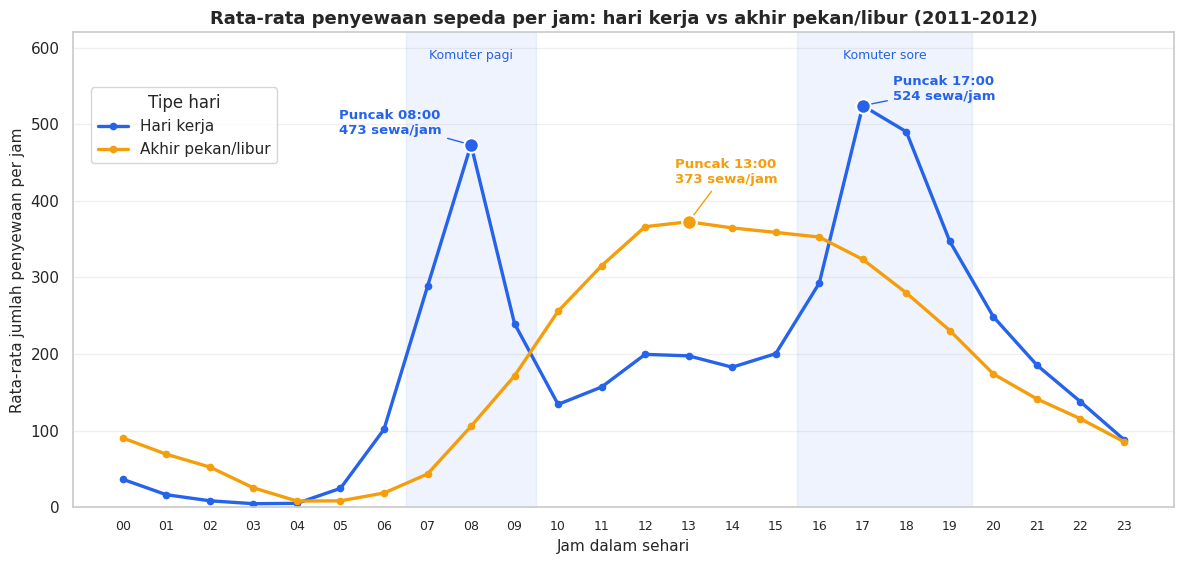

In [21]:
fig, ax = plt.subplots(figsize=(12, 5.8))
ax.axvspan(6.5, 9.5, color=WARNA_KERJA, alpha=0.07)
ax.axvspan(15.5, 19.5, color=WARNA_KERJA, alpha=0.07)
ax.text(8, 585, 'Komuter pagi', ha='center', fontsize=9, color=WARNA_KERJA)
ax.text(17.5, 585, 'Komuter sore', ha='center', fontsize=9, color=WARNA_KERJA)

for tipe, warna in [('Hari kerja', WARNA_KERJA), ('Akhir pekan/libur', WARNA_LIBUR)]:
    ax.plot(hourly_pattern.index, hourly_pattern[tipe], marker='o', ms=4.5, lw=2.4, color=warna, label=tipe)

# Anotasi titik puncak
titik = [
    (int(puncak_pagi['idxmax']), puncak_pagi['max'], WARNA_KERJA, (-95, 8)),
    (int(puncak_sore['idxmax']), puncak_sore['max'], WARNA_KERJA, (22, 4)),
    (int(peak_summary.loc['Akhir pekan/libur', 'jam_puncak']), peak_summary.loc['Akhir pekan/libur', 'rata_rata_sewa_puncak'], WARNA_LIBUR, (-10, 28)),
]
for jam, nilai, warna, offset in titik:
    ax.scatter([jam], [nilai], s=110, color=warna, zorder=5, edgecolor='white', linewidth=1.5)
    ax.annotate(f'Puncak {jam:02d}:00\n{nilai:,.0f} sewa/jam', xy=(jam, nilai), xytext=offset,
                textcoords='offset points', fontsize=9.5, fontweight='bold', color=warna,
                arrowprops=dict(arrowstyle='-', color=warna, lw=1))

ax.set(title='Rata-rata penyewaan sepeda per jam: hari kerja vs akhir pekan/libur (2011-2012)',
       xlabel='Jam dalam sehari', ylabel='Rata-rata jumlah penyewaan per jam', ylim=(0, 620))
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{j:02d}' for j in range(24)], fontsize=9)
ax.legend(title='Tipe hari', loc='upper left', bbox_to_anchor=(0.01, 0.9))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

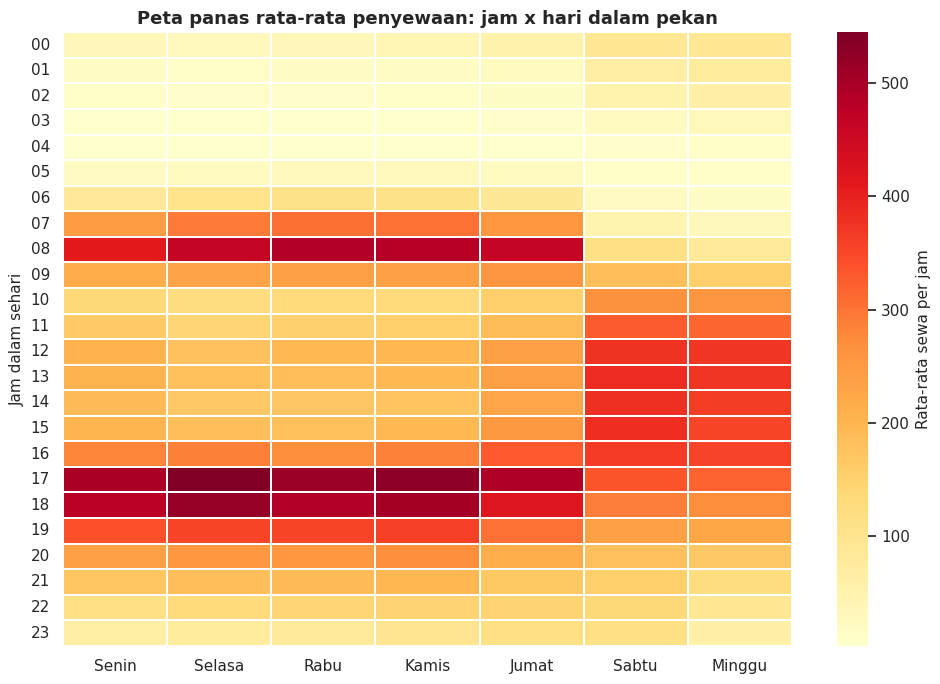

In [22]:
# Pendukung: peta panas jam x hari dalam pekan
urutan_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
heat = hour_df.pivot_table(index='hr', columns='hari', values='cnt', aggfunc='mean')[urutan_hari]

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(heat, cmap='YlOrRd', linewidths=0.3, cbar_kws={'label': 'Rata-rata sewa per jam'}, ax=ax)
ax.set(title='Peta panas rata-rata penyewaan: jam x hari dalam pekan', xlabel='', ylabel='Jam dalam sehari')
ax.set_yticklabels([f'{j:02d}' for j in range(24)], rotation=0)
plt.tight_layout()
plt.show()

**Explanatory insight (Pertanyaan 1):**
- Hari kerja menunjukkan dua gelombang permintaan pada jam berangkat dan pulang kerja (**08:00** dan **17:00**), diselingi lembah pada siang hari. Ini pola komuter.
- Akhir pekan/libur berbentuk satu bukit yang landai dengan puncak pada **13:00**, khas penggunaan rekreasi.
- Peta panas memperlihatkan Senin–Jumat berpola serupa, sedangkan Sabtu–Minggu bergeser ke siang hari. Karena itu hari kerja dan akhir pekan sebaiknya diperlakukan sebagai dua pola operasional yang berbeda.

### Pertanyaan 2 — Bagaimana perbedaan permintaan antar musim dan kategori cuaca?

*Bar chart* dipakai untuk membandingkan rata-rata antar kategori; sumbu dimulai dari nol agar selisih tinggi batang tidak dilebih-lebihkan. Jumlah hari (*n*) dicantumkan agar kategori dengan sampel kecil terbaca jelas. Boxplot dan peta panas melengkapinya dengan sebaran dan interaksi musim x cuaca.

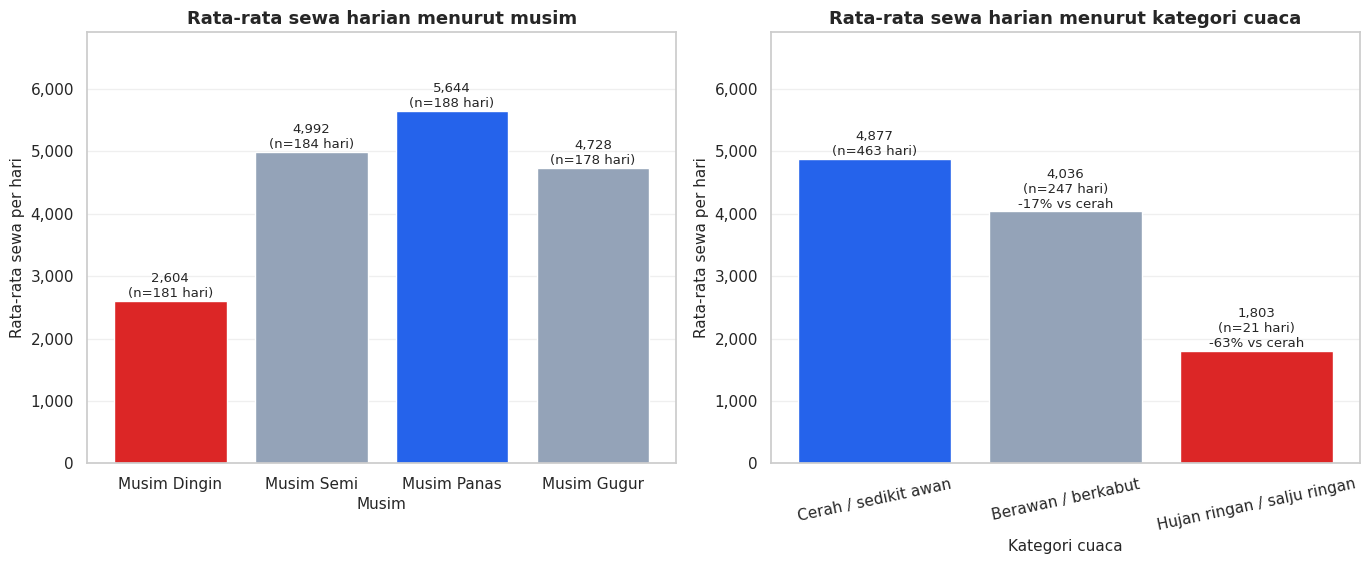

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

# (a) Menurut musim
sp = season_summary.copy()
warna_s = [WARNA_SOROT if v == sp['mean'].min() else WARNA_UTAMA if v == sp['mean'].max() else WARNA_REDUP for v in sp['mean']]
b1 = axes[0].bar(sp.index.astype(str), sp['mean'], color=warna_s)
for rect, (_, r) in zip(b1, sp.iterrows()):
    axes[0].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 60,
                 f"{r['mean']:,.0f}\n(n={int(r['count'])} hari)", ha='center', fontsize=9.5)
axes[0].set(title='Rata-rata sewa harian menurut musim', xlabel='Musim', ylabel='Rata-rata sewa per hari', ylim=(0, 6900))
axes[0].yaxis.set_major_formatter(ribuan)

# (b) Menurut cuaca
wp = weather_summary.sort_values('weathersit')
warna_w = [WARNA_UTAMA, WARNA_REDUP, WARNA_SOROT][:len(wp)]
b2 = axes[1].bar(wp['weather_label'].astype(str), wp['mean'], color=warna_w)
for rect, (_, r) in zip(b2, wp.iterrows()):
    teks = f"{r['mean']:,.0f}\n(n={int(r['count'])} hari)"
    if r['weathersit'] != 1:
        teks += f"\n{r['perubahan_vs_cerah_pct']:+.0f}% vs cerah"
    axes[1].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 60, teks, ha='center', fontsize=9.5)
axes[1].set(title='Rata-rata sewa harian menurut kategori cuaca', xlabel='Kategori cuaca', ylabel='Rata-rata sewa per hari', ylim=(0, 6900))
axes[1].tick_params(axis='x', rotation=12)
axes[1].yaxis.set_major_formatter(ribuan)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

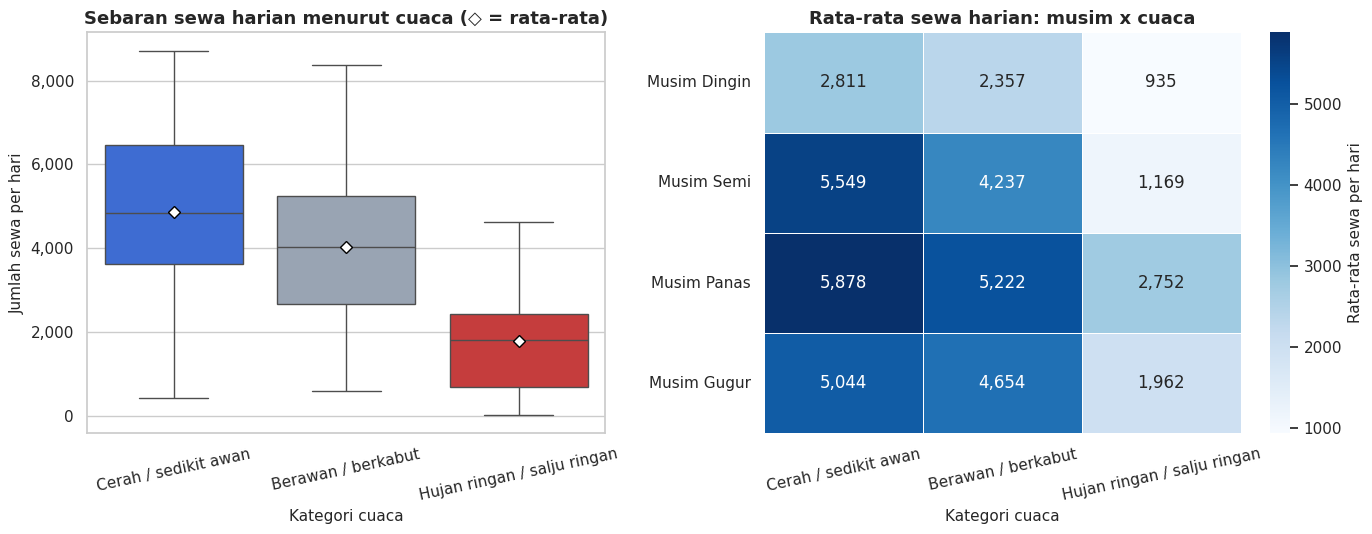

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.15]})

# (a) Sebaran sewa harian per kategori cuaca
data_box = day_df.assign(cuaca=day_df['weather_label'].astype(str))
urutan_cuaca = [weather_labels[k] for k in sorted(day_df['weathersit'].unique())]
sns.boxplot(data=data_box, x='cuaca', y='cnt', order=urutan_cuaca, hue='cuaca', hue_order=urutan_cuaca, legend=False,
            palette=[WARNA_UTAMA, WARNA_REDUP, WARNA_SOROT][:len(urutan_cuaca)],
            showmeans=True, meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black'), ax=axes[0])
axes[0].set(title='Sebaran sewa harian menurut cuaca (◇ = rata-rata)', xlabel='Kategori cuaca', ylabel='Jumlah sewa per hari')
axes[0].yaxis.set_major_formatter(ribuan)
axes[0].tick_params(axis='x', rotation=12)

# (b) Interaksi musim x cuaca
sns.heatmap(pivot_mean, annot=True, fmt=',.0f', cmap='Blues', linewidths=0.5,
            cbar_kws={'label': 'Rata-rata sewa per hari'}, ax=axes[1])
axes[1].set(title='Rata-rata sewa harian: musim x cuaca', xlabel='Kategori cuaca', ylabel='')
axes[1].tick_params(axis='x', rotation=12)
axes[1].tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

**Explanatory insight (Pertanyaan 2):**
- **Musim Dingin** adalah titik terendah (2,604 sewa/hari), sedangkan **Musim Panas** tertinggi (5,644). Tiga musim lainnya berada pada kisaran 4,728–5,644 sewa/hari, sehingga musim dingin adalah satu-satunya fase dengan kebutuhan kapasitas yang jauh lebih kecil (sekitar 51% dari rata-rata tiga musim lainnya).
- Penurunan terbesar terjadi pada **hujan/salju ringan** (**-63%** dibanding cuaca cerah), sedangkan cuaca berawan/berkabut hanya menurunkan permintaan 17%.
- Boxplot memperlihatkan **100%** hari hujan/salju ringan memiliki sewa di bawah median hari cerah (4,844). Peta panas menunjukkan pola serupa di setiap musim: pada setiap baris musim, nilai kolom cuaca cerah > berawan > hujan/salju ringan.
- Perhatikan bahwa kategori hujan/salju ringan hanya 21 hari dan sebagian sel musim x cuaca berisi sedikit hari, sehingga angka pada sel-sel kecil bersifat indikatif.

## Analisis Lanjutan (Opsional)

Sebagai analisis tambahan **tanpa machine learning**, dilakukan segmentasi manual (*binning*) untuk memperdalam dua pertanyaan di atas:

1. **Binning suhu (°C)** — rentang suhu apa yang berasosiasi dengan permintaan tertinggi? Ini memperkuat temuan musim dan cuaca.
2. **Segmentasi waktu dalam sehari** — seberapa besar perbedaan intensitas tiap segmen waktu antara hari kerja dan akhir pekan/libur? Ini menerjemahkan pola jam menjadi segmen operasional yang mudah dipakai.

In [25]:
# Binning suhu dalam derajat Celsius
day_df['kelompok_suhu'] = pd.cut(day_df['temp_c'], bins=[-np.inf, 10, 18, 26, np.inf],
                                 labels=['< 10 °C', '10-18 °C', '18-26 °C', '> 26 °C'])
suhu_summary = day_df.groupby('kelompok_suhu', observed=True)['cnt'].agg(['count', 'mean', 'median', 'std'])
suhu_summary['perubahan_vs_terendah_pct'] = (suhu_summary['mean'] / suhu_summary['mean'].iloc[0] - 1) * 100
display(suhu_summary.round(1))

# Rata-rata sewa per jam pada tiap segmen waktu dan tipe hari
segmen_summary = hour_df.groupby(['segmen_waktu', 'day_type'], observed=True)['cnt'].mean().unstack('day_type')
segmen_summary['rasio_kerja_vs_libur'] = segmen_summary['Hari kerja'] / segmen_summary['Akhir pekan/libur']
display(segmen_summary.round(2))

,count,mean,median,std,perubahan_vs_terendah_pct
kelompok_suhu,,,,,
< 10 °C,240,"2,892.60","2,709.00","1,438.30",0.00
10-18 °C,188,"4,693.60","4,569.50","1,778.80",62.30
18-26 °C,217,"5,711.60","5,423.00","1,477.30",97.50
> 26 °C,86,"5,542.20","5,399.50","1,296.70",91.60


day_type,Akhir pekan/libur,Hari kerja,rasio_kerja_vs_libur
segmen_waktu,,,
Dini hari (00-05),42.32,15.95,0.38
Pagi (06-09),84.82,275.69,3.25
Siang (10-15),338.95,178.64,0.53
Sore (16-19),296.70,413.51,1.39
Malam (20-23),129.14,165.11,1.28


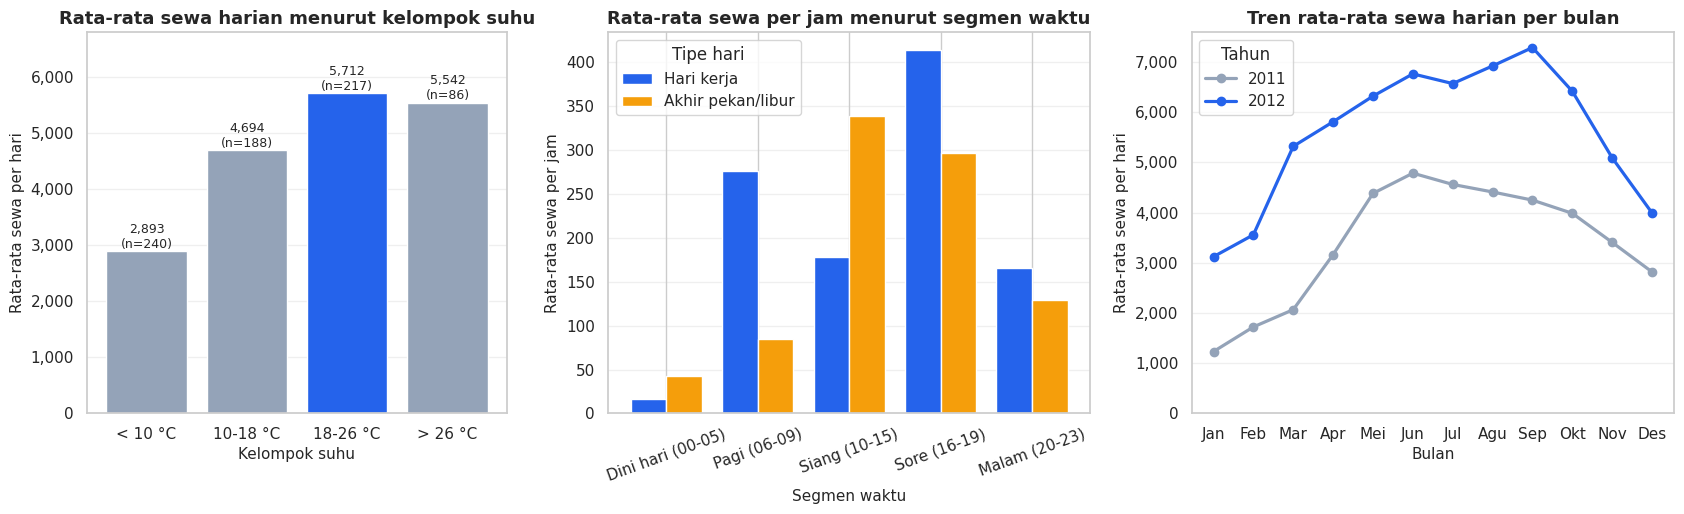

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), gridspec_kw={'width_ratios': [1, 1.15, 1.15]})

# (a) Binning suhu
warna_t = [WARNA_REDUP] * len(suhu_summary)
warna_t[int(np.argmax(suhu_summary['mean'].values))] = WARNA_UTAMA
bars = axes[0].bar(suhu_summary.index.astype(str), suhu_summary['mean'], color=warna_t)
for rect, (_, r) in zip(bars, suhu_summary.iterrows()):
    axes[0].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 60, f"{r['mean']:,.0f}\n(n={int(r['count'])})", ha='center', fontsize=9)
axes[0].set(title='Rata-rata sewa harian menurut kelompok suhu', xlabel='Kelompok suhu', ylabel='Rata-rata sewa per hari', ylim=(0, 6800))
axes[0].yaxis.set_major_formatter(ribuan)

# (b) Segmen waktu x tipe hari
seg = segmen_summary[['Hari kerja', 'Akhir pekan/libur']]
seg.plot(kind='bar', ax=axes[1], color=[WARNA_KERJA, WARNA_LIBUR], width=0.78)
axes[1].set(title='Rata-rata sewa per jam menurut segmen waktu', xlabel='Segmen waktu', ylabel='Rata-rata sewa per jam')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='Tipe hari')

# (c) Tren bulanan 2011 vs 2012
for tahun, warna in [(2011, WARNA_REDUP), (2012, WARNA_UTAMA)]:
    axes[2].plot(tren_bulanan.index, tren_bulanan[tahun], marker='o', lw=2.3, color=warna, label=str(tahun))
axes[2].set(title='Tren rata-rata sewa harian per bulan', xlabel='Bulan', ylabel='Rata-rata sewa per hari', ylim=(0, None))
axes[2].legend(title='Tahun')
axes[2].yaxis.set_major_formatter(ribuan)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

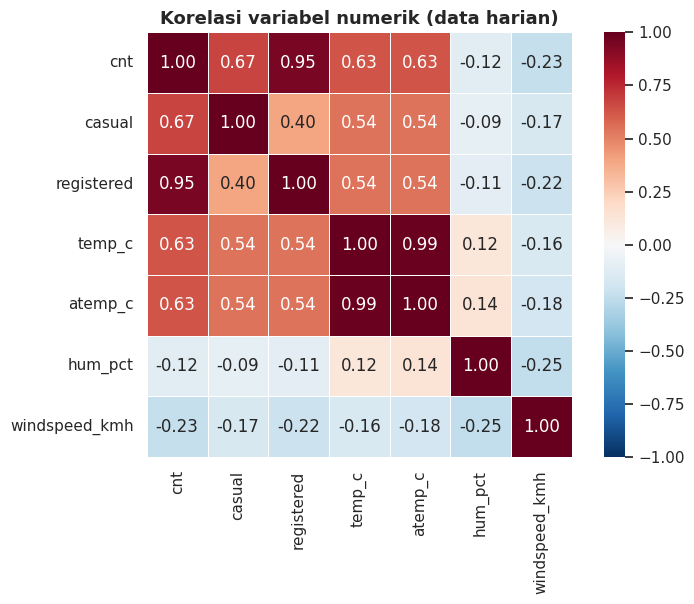

In [27]:
# Korelasi antar variabel numerik
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5, square=True, ax=ax)
ax.set_title('Korelasi variabel numerik (data harian)')
plt.tight_layout()
plt.show()

**Insight analisis lanjutan:**
- Permintaan naik seiring suhu: kelompok **18-26 °C** menghasilkan rata-rata **5,712 sewa/hari**, sekitar **97%** lebih tinggi dibanding kelompok **< 10 °C** (2,893 sewa/hari). Permintaan kemudian relatif mendatar pada kelompok > 26 °C (5,542 sewa/hari). Pola ini konsisten dengan temuan bahwa musim dingin adalah musim terlemah.
- Segmen **Sore (16–19)** adalah yang paling padat pada hari kerja (414 sewa/jam, 1.4x akhir pekan), disusul **Pagi (06–09)** (276 sewa/jam, 3.3x akhir pekan). Sebaliknya, pada segmen **Siang (10–15)** akhir pekan/libur lebih tinggi (339 vs 179 sewa/jam).
- Kurva tren bulanan 2012 selalu berada di atas 2011 dengan bentuk musiman yang sama, menandakan pertumbuhan layanan yang stabil.
- Korelasi suhu dengan total sewa (r ≈ 0.63) adalah yang terkuat di antara variabel cuaca; korelasi tidak menunjukkan sebab-akibat, dan suhu berkorelasi dengan musim.

## Conclusion & Recommendation

### Kesimpulan

**Pertanyaan 1 — Pola jam puncak hari kerja vs akhir pekan/libur**
Pada hari kerja permintaan memuncak dua kali: **08:00** (473 sewa/jam) dan **17:00** (524 sewa/jam), yang merupakan pola komuter. Pada akhir pekan/libur puncaknya tunggal dan lebih rendah pada **13:00** (373 sewa/jam), dengan permintaan tinggi sepanjang siang. Puncak hari kerja **41% lebih tinggi** daripada puncak akhir pekan/libur, dan jam sibuk (07–09 dan 16–19) menyumbang **58%** penyewaan hari kerja. Hari kerja didominasi pengguna terdaftar (pengguna kasual hanya 13%), sedangkan pada akhir pekan/libur pengguna kasual naik menjadi 32%.

**Pertanyaan 2 — Perbedaan antar musim dan cuaca**
Rata-rata sewa harian tertinggi terjadi pada **Musim Panas** (5,644/hari) dan terendah pada **Musim Dingin** (2,604/hari), selisih **54%**. Dibanding cuaca cerah (4,877/hari), permintaan turun **17%** saat berawan/berkabut dan **63%** saat hujan/salju ringan (1,803/hari). Penurunan akibat cuaca buruk tetap muncul di dalam setiap musim, sehingga bukan sekadar efek musim.

**Temuan tambahan**
- Permintaan naik tajam dari kelompok suhu < 10 °C (2,893/hari) ke 18–26 °C (5,712/hari), lalu relatif mendatar pada > 26 °C (5,542/hari).
- Permintaan tumbuh **65%** dari 2011 ke 2012, jadi kapasitas dasar perlu dievaluasi tiap tahun.

**Keterbatasan analisis**
- Hubungan musim, cuaca, dan suhu bersifat deskriptif/asosiatif, bukan sebab-akibat.
- Kategori hujan/salju ringan hanya 21 hari dan kategori hujan lebat hanya 3 jam, sehingga estimasinya kurang stabil.
- Data hanya mencakup dua tahun dan satu kota; data tidak memuat lokasi stasiun sehingga rekomendasi lokasi redistribusi perlu dilengkapi data stasiun.

### Rekomendasi action item
1. **Jadwalkan redistribusi pada hari kerja sebelum puncak komuter.** Siapkan stok sepeda sebelum 07:00 untuk puncak pagi dan sebelum 16:00 untuk puncak sore, lalu lakukan *rebalancing* setelah puncak. Prioritaskan 08:00 dan 17:00 karena kedua jam ini terpadat. Titik lokasi (misalnya area permukiman, stasiun transit, atau perkantoran) perlu diverifikasi dengan data stasiun karena dataset ini tidak memuat lokasi.
2. **Gunakan jadwal terpisah untuk akhir pekan/libur.** Pindahkan fokus armada ke area rekreasi dan wisata mulai pukul 10:00–16:00, dengan puncak sekitar 13:00, dan siapkan layanan untuk pengguna kasual (penyewaan tanpa registrasi).
3. **Rancang kapasitas musiman.** Pertahankan kapasitas penuh pada tiga musim selain Musim Dingin, dan manfaatkan **Musim Dingin** untuk perawatan armada serta penjadwalan perbaikan karena permintaan paling rendah.
4. **Buat protokol cuaca buruk.** Saat prakiraan hujan/salju, kurangi redistribusi dan alihkan sumber daya ke perawatan; perkirakan permintaan sekitar **63% lebih rendah** dibanding cuaca cerah (estimasi kasar karena hanya 21 hari). Jangan mengubah armada hanya dari satu indikator; gabungkan dengan prakiraan cuaca dan data permintaan terbaru.
5. **Pantau dan evaluasi berkala.** Lacak rata-rata sewa per jam, rasio hari kerja vs akhir pekan, dan dampak cuaca setiap bulan, serta lengkapi dengan data lokasi stasiun untuk menentukan titik redistribusi yang spesifik.